# 2. Data Preparation

**Projeto:** Classificação de Ataques de Cibersegurança

**Objetivo:** preparar os textos, eliminar duplicados, filtrar categorias pouco representadas e dividir os dados em treino, validação e teste.

Este notebook **reutiliza** as funções existentes em `src/data_preparation.py`, evitando duplicar a implementação.

## 1. Importar as funções do projeto

A pasta `src` contém o código de preparação utilizado no treino original.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Aceita execução a partir da raiz do projeto ou da pasta notebooks.
root = Path.cwd()
if not (root / "src" / "data_preparation.py").exists():
    root = root.parent
if not (root / "src" / "data_preparation.py").exists():
    raise FileNotFoundError("Abre o projeto_AI no VS Code antes de executar o notebook.")
sys.path.insert(0, str(root))
from src.ivan import data_preparation as dp

path = root / "dataset" / "raw" / "Attack_Dataset.csv"
print("Dataset:", path)


Dataset: d:\CyberSecurity-ISTEC\projeto_AI_3\Projeto-IAAC\dataset\raw\Attack_Dataset.csv


## 2. Carregamento e limpeza

O módulo remove colunas auxiliares, trata valores em falta, normaliza espaços, combina os campos textuais em `Combined_Text`, elimina textos idênticos e mantém categorias com pelo menos 100 amostras.

In [3]:
df_original = dp.load_data(path)
df_clean = dp.clean_data(df_original)

print("Registos originais:", len(df_original))
print("Registos após limpeza:", len(df_clean))
print("Categorias após limpeza:", df_clean["Category"].nunique())
display(df_clean[["Combined_Text", "Category"]].head(3))


Dimensões originais: (14133, 16)
Registos após limpeza: 12891
Número de classes: 27
Registos originais: 14133
Registos após limpeza: 12891
Categorias após limpeza: 27


,Combined_Text,Category
0,Authentication Bypass via SQL Injection A logi...,Mobile Security
1,Union-Based SQL Injection This attack occurs w...,AI Agents & LLM Exploits
2,Error-Based SQL Injection This attack occurs w...,AI Agents & LLM Exploits


## 3. Distribuição das categorias após a limpeza

A distribuição das classes ajuda a perceber o equilíbrio do conjunto utilizado na modelação.

,registos
Category,
Physical / Hardware Attacks,548
Quantum Cryptography & Post-Quantum Threats,542
Malware & Threat,528
Wireless Attacks (Advanced),520
Insider Threat,514
Blue Team,503
Cryptography Attacks,501
Mobile Security,500
Email & Messaging Protocol Exploits,500


C:\Users\Utilizador\AppData\Local\Temp\ipykernel_14456\1639728702.py:6: UserWarning: Glyph 128737 (\N{SHIELD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128737 (\N{SHIELD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


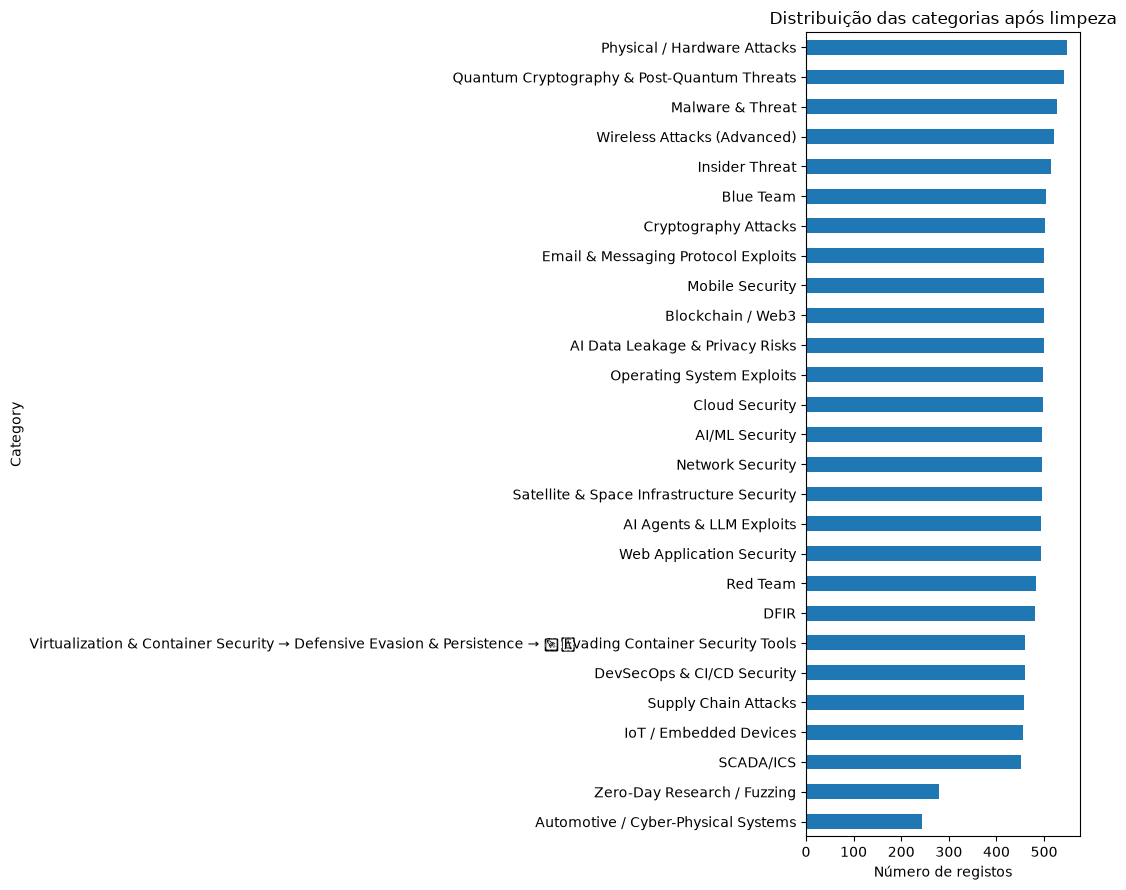

In [4]:
counts = df_clean["Category"].value_counts()
display(counts.to_frame("registos"))
counts.sort_values().plot(kind="barh", figsize=(11, 9))
plt.title("Distribuição das categorias após limpeza")
plt.xlabel("Número de registos")
plt.tight_layout()
plt.show()


## 4. Divisão estratificada: 70% / 15% / 15%

A estratificação procura preservar a proporção das categorias em cada conjunto. O teste fica reservado para a avaliação final, sem participar na seleção do modelo.

In [ ]:
X, y = dp.split_features_target(df_clean)
X_train, X_val, X_test, y_train, y_val, y_test = dp.split_train_validation_test(X, y)

summary = pd.DataFrame({
    "Conjunto": ["Treino", "Validação", "Teste"],
    "Registos": [len(X_train), len(X_val), len(X_test)],
})
summary["Percentagem"] = (100 * summary["Registos"] / len(X)).round(2)
display(summary)



Distribuição das classes:
Category
Physical / Hardware Attacks                                                                                    548
Quantum Cryptography & Post-Quantum Threats                                                                    542
Malware & Threat                                                                                               528
Wireless Attacks (Advanced)                                                                                    520
Insider Threat                                                                                                 514
Blue Team                                                                                                      503
Cryptography Attacks                                                                                           501
Mobile Security                                                                                                500
Email & Messaging Protocol Exploits         

,Conjunto,Registos,Percentagem
0,Treino,9023,69.99
1,Validação,1934,15.00
2,Teste,1934,15.00


## 5. Verificação de textos repetidos entre conjuntos

Verificamos se existem **textos exatamente iguais** em conjuntos diferentes. Esta verificação não exclui semelhanças de conteúdo ou outras formas de fuga de informação.

In [ ]:
train_texts = set(X_train)
val_texts = set(X_val)
test_texts = set(X_test)

print("Treino ∩ Validação:", len(train_texts & val_texts))
print("Treino ∩ Teste:", len(train_texts & test_texts))
print("Validação ∩ Teste:", len(val_texts & test_texts))


Treino ∩ Validação: 0
Treino ∩ Teste: 0
Validação ∩ Teste: 0


## 6. Conclusões

- A preparação transforma várias colunas de texto numa única característica: **`Combined_Text`**.
- O filtro de **100 exemplos por categoria** é uma decisão metodológica do projeto.
- O conjunto de dados é dividido de forma **estratificada** em treino, validação e teste.
- O **TF-IDF não é ajustado nesta etapa**: é ajustado dentro do Pipeline durante o treino, evitando aprender vocabulário a partir do conjunto de teste.
- Os valores esperados na versão anteriormente executada são **12.891 registos, 27 categorias, 9.023 treino, 1.934 validação e 1.934 teste**. Confirmar estes números nos resultados acima antes de os apresentar.

**Próxima etapa:** `03_modeling.ipynb` — comparação de algoritmos com validação cruzada.